In [12]:
import pandas as pd
import numpy as np
from machinelearningproject_ct4101.utils import plot_distribution

raw_dataset_path = "../../../data/raw/online_shoppers_intention.csv"

### The Dataset
- Name : Online Shoppers Purchasing Intention Dataset
- Creators : C.Sakar, Yomi Kastro
- License: CC BY 4.0
- Description:
    The dataset consists of 17 features belonging to 12,330 shopping sessions
- Target : `Revenue` : Boolean on whether visitor made a purchase or not
-  [Link](https://archive.ics.uci.edu/dataset/468/online+shoppers+purchasing+intention+dataset)


#### Features:
[Their paper](https://www.semanticscholar.org/paper/Real-time-prediction-of-online-shoppers%E2%80%99-purchasing-Sakar-Polat/747e098f85ca2d20afd6313b11242c0c427e6fb3) and the [UCI Dataset](https://archive.ics.uci.edu/dataset/468/online+shoppers+purchasing+intention+dataset) were used to source the descriptions

**Browsing behaviour features**
- `Administrative` : number of account management pages visited (int64)
- `Administrative_Duration` : total time in seconds spent on account management pages (float64)
- `Informational` : number of website informational pages visited (int64)
- `Informational_Duration` : total time in seconds spent on informational pages (float64)
- `ProductRelated` : number of pages product related pages visited (int64)
-  `ProductRelated_Duration`: total time in seconds spent on product related pages (float64)

**Metrics**
- `BounceRates` : avg percentage of visitors who enter the site from that page and then leave ("bounce") without triggering any other requests to the analytics server during that session (float64)
- `ExitRates` : avg average exit rate of all pages visited by a shopper (float64)
- `PageValues`:  average value for a web page that a user visited before completing an e-commerce transaction. (float64)

**Temporal**
- `SpecialDay` : closeness of the site visiting time to a special day (float64)
- `Month` : month of visit date (str)
- `Weekend` : bool indicating whether visited on weekend or not (bool)

**Fingerprinting**
- `OperatingSystems` : Operating System of the visitor (Category int64)
- `Browser` : Browser of the visitor  (Category int64)
- `Region` : Geographic region of the visitor  (Category int64)
- `TrafficType` : How the visitor reached the website  (Category int64)
- `VisitorType` : Visitor Type (New, Returning or  Other) (Str)

**Target**
- `Revenue` : Boolean whether visitor made a purchase (Bool)

___
### Key Obervations
- No NaN values
- 125 duplicated rows, however they correspond to very short visits, and are more than likely just very short sessions with similar activity, so need need to dedupe
- Need to scale/transform the numerical values, a majority of them are heavily right skewed with a few large outliers. 
- Target class is unevenly distributed, roughly 85% of visits did not make a purchase, so a model predicting False 100% of the time would still obtain roughly 85% accuracy.
- We need to stratify the train/test splits
- `Month` and `VisitorType` are not encoded, we'll have to encode them
___

### Load Data and Inspect 

Our dataset has 17 features, and 1 target feature, with 12330 observations

In [13]:
df = pd.read_csv(raw_dataset_path)
df.shape

(12330, 18)

___
We see our dataset contains no null values. 

In [14]:
df.info()
df.isnull().sum()

<class 'pandas.DataFrame'>
RangeIndex: 12330 entries, 0 to 12329
Data columns (total 18 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   Administrative           12330 non-null  int64  
 1   Administrative_Duration  12330 non-null  float64
 2   Informational            12330 non-null  int64  
 3   Informational_Duration   12330 non-null  float64
 4   ProductRelated           12330 non-null  int64  
 5   ProductRelated_Duration  12330 non-null  float64
 6   BounceRates              12330 non-null  float64
 7   ExitRates                12330 non-null  float64
 8   PageValues               12330 non-null  float64
 9   SpecialDay               12330 non-null  float64
 10  Month                    12330 non-null  str    
 11  OperatingSystems         12330 non-null  int64  
 12  Browser                  12330 non-null  int64  
 13  Region                   12330 non-null  int64  
 14  TrafficType              12330 no

Administrative             0
Administrative_Duration    0
Informational              0
Informational_Duration     0
ProductRelated             0
ProductRelated_Duration    0
BounceRates                0
ExitRates                  0
PageValues                 0
SpecialDay                 0
Month                      0
OperatingSystems           0
Browser                    0
Region                     0
TrafficType                0
VisitorType                0
Weekend                    0
Revenue                    0
dtype: int64

In [15]:
df.head(3)

,Administrative,Administrative_Duration,Informational,Informational_Duration,ProductRelated,ProductRelated_Duration,BounceRates,ExitRates,PageValues,SpecialDay,Month,OperatingSystems,Browser,Region,TrafficType,VisitorType,Weekend,Revenue
0,0,0.0,0,0.0,1,0.0,0.2,0.2,0.0,0.0,Feb,1,1,1,1,Returning_Visitor,False,False
1,0,0.0,0,0.0,2,64.0,0.0,0.1,0.0,0.0,Feb,2,2,1,2,Returning_Visitor,False,False
2,0,0.0,0,0.0,1,0.0,0.2,0.2,0.0,0.0,Feb,4,1,9,3,Returning_Visitor,False,False


In [16]:
df.tail(3)

,Administrative,Administrative_Duration,Informational,Informational_Duration,ProductRelated,ProductRelated_Duration,BounceRates,ExitRates,PageValues,SpecialDay,Month,OperatingSystems,Browser,Region,TrafficType,VisitorType,Weekend,Revenue
12327,0,0.0,0,0.0,6,184.25,0.083333,0.086667,0.0,0.0,Nov,3,2,1,13,Returning_Visitor,True,False
12328,4,75.0,0,0.0,15,346.00,0.000000,0.021053,0.0,0.0,Nov,2,2,3,11,Returning_Visitor,False,False
12329,0,0.0,0,0.0,3,21.25,0.000000,0.066667,0.0,0.0,Nov,3,2,1,2,New_Visitor,True,False


___
We see our numeric values have significantly different ranges. We should scale them so prevent features with large values from disproportionately influencing our model 

In [17]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
Administrative,12330.0,2.315166,3.321784,0.0,0.000000,1.000000,4.000000,27.000000
Administrative_Duration,12330.0,80.818611,176.779107,0.0,0.000000,7.500000,93.256250,3398.750000
Informational,12330.0,0.503569,1.270156,0.0,0.000000,0.000000,0.000000,24.000000
Informational_Duration,12330.0,34.472398,140.749294,0.0,0.000000,0.000000,0.000000,2549.375000
ProductRelated,12330.0,31.731468,44.475503,0.0,7.000000,18.000000,38.000000,705.000000
ProductRelated_Duration,12330.0,1194.746220,1913.669288,0.0,184.137500,598.936905,1464.157214,63973.522230
BounceRates,12330.0,0.022191,0.048488,0.0,0.000000,0.003112,0.016813,0.200000
ExitRates,12330.0,0.043073,0.048597,0.0,0.014286,0.025156,0.050000,0.200000
PageValues,12330.0,5.889258,18.568437,0.0,0.000000,0.000000,0.000000,361.763742
SpecialDay,12330.0,0.061427,0.198917,0.0,0.000000,0.000000,0.000000,1.000000


___
We see we have 125 duplicated rows. 
Inspecting these we see these duplicates represent very short browsing sessions with little no activity. These are likely just very short sessions, having similar activity so we decide to keep them

In [18]:
df.duplicated().sum()

np.int64(125)

In [19]:
duplicates = df[df.duplicated()]
duplicates

,Administrative,Administrative_Duration,Informational,Informational_Duration,ProductRelated,ProductRelated_Duration,BounceRates,ExitRates,PageValues,SpecialDay,Month,OperatingSystems,Browser,Region,TrafficType,VisitorType,Weekend,Revenue
158,0,0.0,0,0.0,1,0.0,0.2,0.2,0.0,0.0,Feb,1,1,1,3,Returning_Visitor,False,False
159,0,0.0,0,0.0,1,0.0,0.2,0.2,0.0,0.0,Feb,3,2,3,3,Returning_Visitor,False,False
178,0,0.0,0,0.0,1,0.0,0.2,0.2,0.0,0.0,Feb,3,2,3,3,Returning_Visitor,False,False
418,0,0.0,0,0.0,1,0.0,0.2,0.2,0.0,0.0,Mar,1,1,1,1,Returning_Visitor,True,False
456,0,0.0,0,0.0,1,0.0,0.2,0.2,0.0,0.0,Mar,2,2,4,1,Returning_Visitor,False,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
11934,0,0.0,0,0.0,1,0.0,0.2,0.2,0.0,0.0,Dec,1,1,1,2,New_Visitor,False,False
11938,0,0.0,0,0.0,1,0.0,0.2,0.2,0.0,0.0,Dec,1,1,4,1,Returning_Visitor,True,False
12159,0,0.0,0,0.0,1,0.0,0.2,0.2,0.0,0.0,Dec,1,1,1,3,Returning_Visitor,False,False
12180,0,0.0,0,0.0,1,0.0,0.2,0.2,0.0,0.0,Dec,1,13,9,20,Returning_Visitor,False,False


In [20]:
duplicates.describe().T

,count,mean,std,min,25%,50%,75%,max
Administrative,125.0,0.0000,0.000000,0.0,0.0,0.0,0.0,0.0
Administrative_Duration,125.0,0.0000,0.000000,0.0,0.0,0.0,0.0,0.0
Informational,125.0,0.0000,0.000000,0.0,0.0,0.0,0.0,0.0
Informational_Duration,125.0,0.0000,0.000000,0.0,0.0,0.0,0.0,0.0
ProductRelated,125.0,1.0560,0.230847,1.0,1.0,1.0,1.0,2.0
ProductRelated_Duration,125.0,0.0000,0.000000,0.0,0.0,0.0,0.0,0.0
BounceRates,125.0,0.2000,0.000000,0.2,0.2,0.2,0.2,0.2
ExitRates,125.0,0.2000,0.000000,0.2,0.2,0.2,0.2,0.2
PageValues,125.0,0.0000,0.000000,0.0,0.0,0.0,0.0,0.0
SpecialDay,125.0,0.0112,0.089096,0.0,0.0,0.0,0.0,0.8


___

### Distribution of Features
Our dataset contains 10 numerical features and 8 categorical features (including the target, Revenue)

#### Plotting numerical features
Observations:
- Almost all of our features are heavily right skewed, indicating the need for some scaling / transform such as `RobustScaler` or log transform

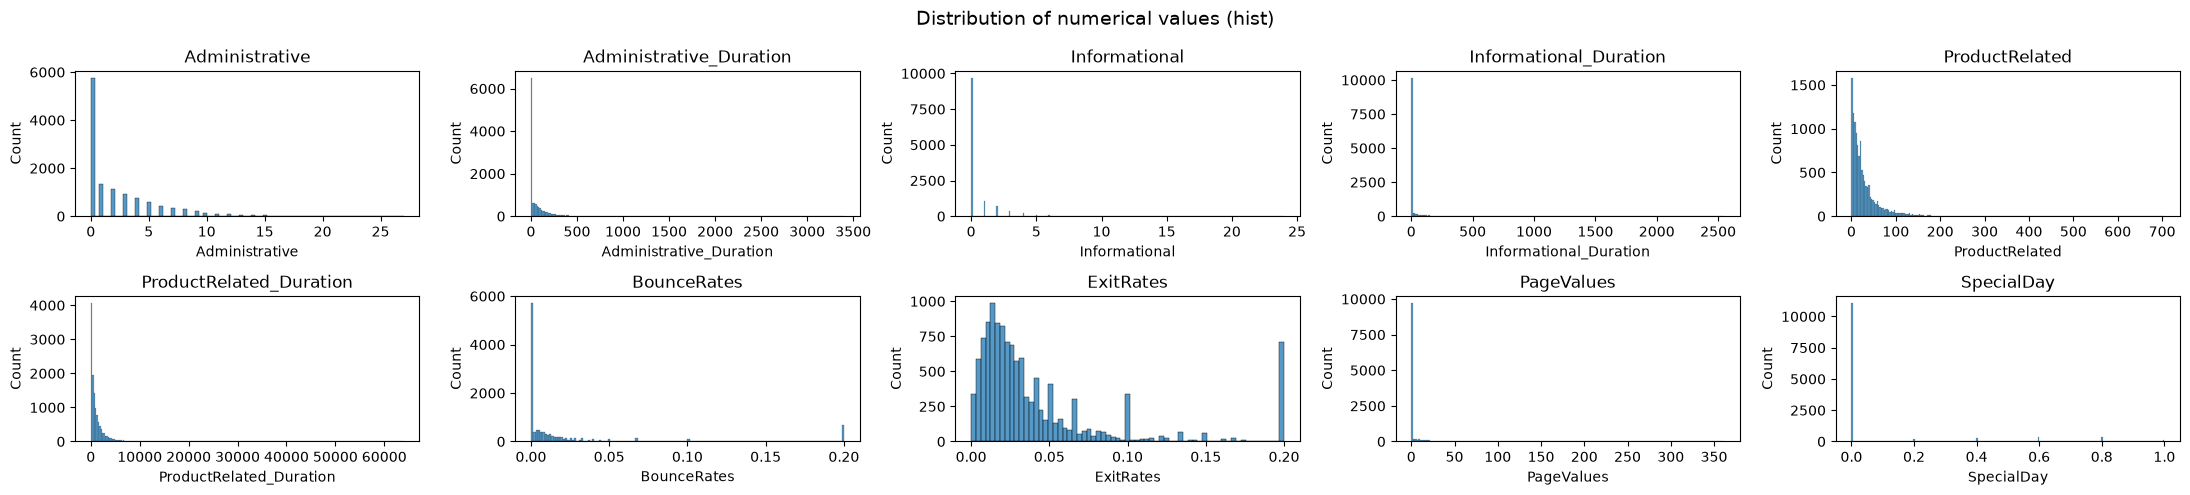

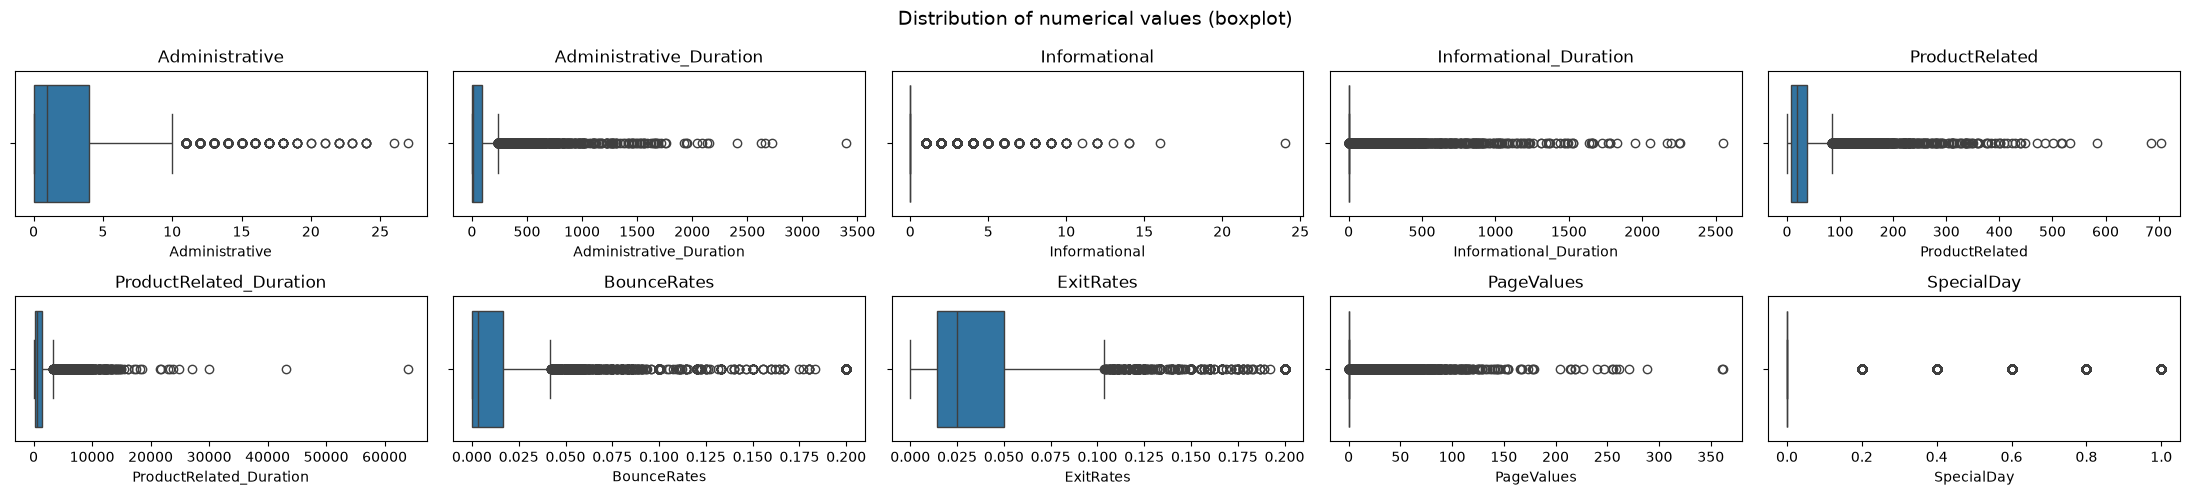

In [21]:
numerical = ['Administrative', 'Administrative_Duration', 'Informational', 'Informational_Duration', 'ProductRelated', 'ProductRelated_Duration', 'BounceRates', 'ExitRates', 'PageValues', 'SpecialDay']


plot_distribution(df, "hist", 2,5,"Distribution of numerical values (hist)", numerical)

plot_distribution(df, "boxplot", 2,5,"Distribution of numerical values (boxplot)", numerical)

#### Plotting categorical features
Observations:
- A majority (roughly 95%) of `OperatingSystems` were of categories 1,2,3 or 4
- A majority (roughly 80%) of `Browser` were of category 1 or 2
- `Region` as roughly uniform, with a majority being category 1
- A majority (65%) was from categories 1,2,3
- A majority (80%) of visitors were returning visitors
- A majority (70%) of visits were during the week
- A majority of visits mainly occurred in March, May, November and December
- A majority (80%) of visits did not result in a purchase

Our Month column is missing Janurary and April

Browser, Operating System, Region, TrafficType are using Ordinal encoding, even though they're nominal categories

Visitor Type is not encoded, we need to encode it. 

Month is not encoded, we need to encode it, using cyclical encoding


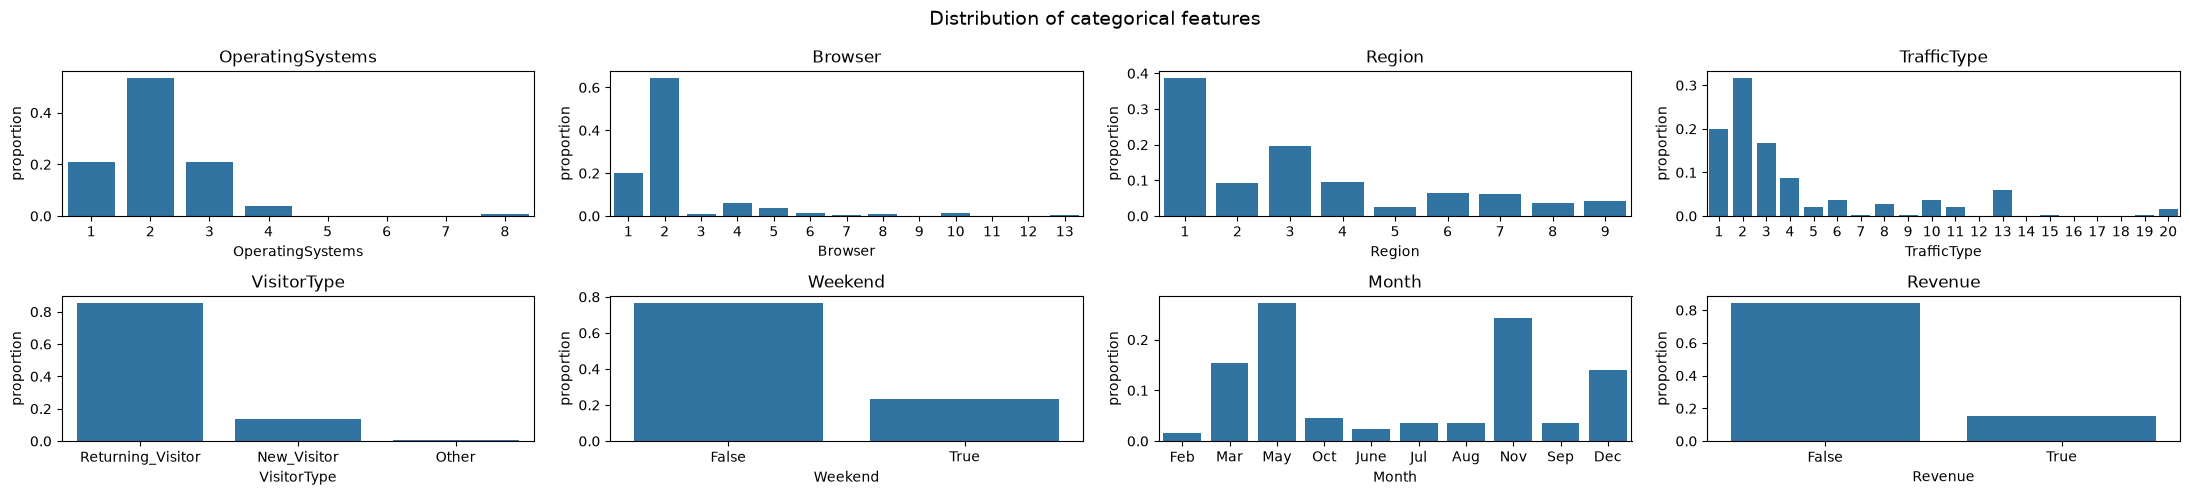

In [ ]:
categorical_cols = ['OperatingSystems', 'Browser', 'Region', 'TrafficType', 'VisitorType', 'Weekend', 'Month', 'Revenue']
plot_distribution(df, 'counts', 2, 4, 'Distribution of categorical features', categorical_cols)